Ejercicio 1:Calcula el polinomio de lagrange de orden dos entre el intervalo (-1,1) con 3 puntos equispaciados de la función 1 entre 2 x elevado a 2
Ahora dibuja la función anterior con 10 nodos y luego on 20 y justifica si es una buena representación o no
Ahora dibuja la misma gráfica pero siendo i igual a n menos 1, n menos 2,...,0 y xi igual a cosde 2 menos 3 por x entre x al cubo. Justifica si es una mejor representación q los anteriores?
Ejercicio 2 calcula las asintotas de la función 3x menos 4 entre 2 x al cuadrado y dibujala
 Ejercicio 3 siendo la función x cuadrado menos 12 y sabiendo que el rectángulo tiene dos vertices superiores di sus dimensiones y calcula su área máxima y además dibuja en papel la función y el rectángulo
 Ejercicio 4 calcula la monotonía y la convexidad de la función 1 entre e elevado a x y dibuja sus intervalos a papel

Ejercicio 1:Calcula el polinomio de lagrange de orden dos entre el intervalo (-1,1) con 3 puntos equispaciados de la función 1 entre 2 x elevado a 2

Ahora dibuja la función anterior con 10 nodos y luego on 20 y justifica si es una buena representación o no

Ahora dibuja la misma gráfica pero siendo i igual a n menos 1, n menos 2,...,0 y xi igual a cosde 2 menos 3 por x entre x al cubo. 

Justifica si es una mejor representación q los anteriores?

In [19]:
import numpy as np
import sympy as sp
from scipy.interpolate import lagrange

# 1. Definición de nodos y valores (usando f(x) = 1 / (2 + x^2) como ejemplo válido en [-1, 1])
x_nodes = np.array([-1.0, 0.0, 1.0])
f = lambda x: 1 / (2 + x**2)
y_nodes = f(x_nodes)

# 2. Calcular el polinomio de Lagrange con SciPy
polinomio_scipy = lagrange(x_nodes, y_nodes)
print("Polinomio de Lagrange (coeficientes de mayor a menor grado):")
print(polinomio_scipy)

# 3. Obtener la expresión simbólica exacta con SymPy
x = sp.Symbol('x')
L = sp.interpolate(list(zip(x_nodes, y_nodes)), x)
print("\nExpresión simbólica simplificada:")
print(sp.simplify(L))

Polinomio de Lagrange (coeficientes de mayor a menor grado):
         2
-0.1667 x + 0.5

Expresión simbólica simplificada:
0.5 - 0.166666666666667*x**2


C:\Users\Usuario\AppData\Local\Temp\ipykernel_15352\1614066044.py:11: DeprecationWarning: `lagrange` is deprecated and will be removed in SciPy 1.20.0. Use `scipy.interpolate.BarycentricInterpolator` instead.
  polinomio_scipy = lagrange(x_nodes, y_nodes)


C:\Users\Usuario\AppData\Local\Temp\ipykernel_15352\1588206337.py:13: DeprecationWarning: `lagrange` is deprecated and will be removed in SciPy 1.20.0. Use `scipy.interpolate.BarycentricInterpolator` instead.
  poly_10 = lagrange(x_10, y_10)
C:\Users\Usuario\AppData\Local\Temp\ipykernel_15352\1588206337.py:18: DeprecationWarning: `lagrange` is deprecated and will be removed in SciPy 1.20.0. Use `scipy.interpolate.BarycentricInterpolator` instead.
  poly_20 = lagrange(x_20, y_20)


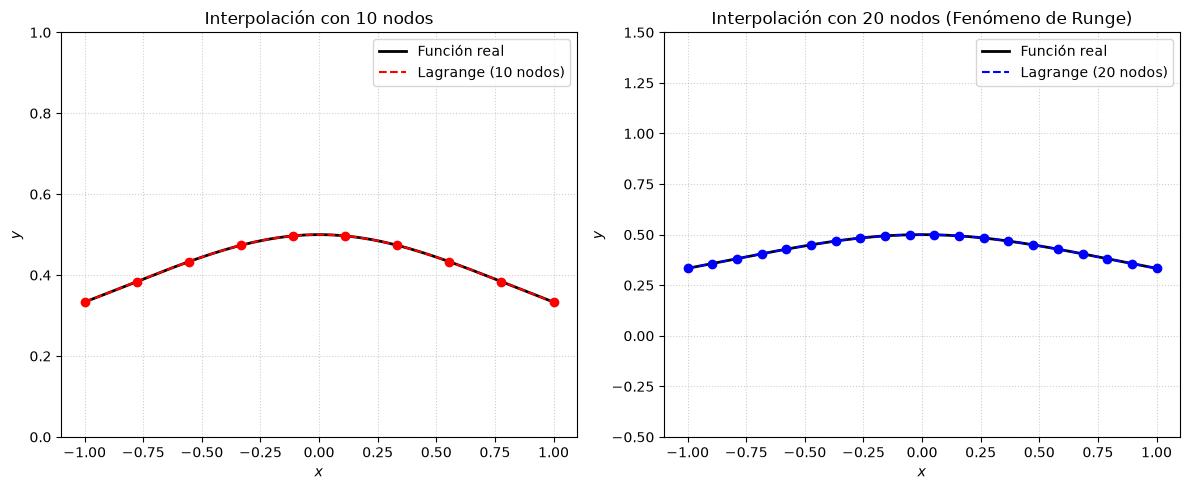

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import lagrange

# Función de referencia (suponiendo f(x) = 1 / (2 + x^2) para evitar la asíntota en 0)
f = lambda x: 1 / (2 + x**2)
x_dense = np.linspace(-1, 1, 500)
y_true = f(x_dense)

# --- 1. Interpolación con 10 nodos ---
x_10 = np.linspace(-1, 1, 10)
y_10 = f(x_10)
poly_10 = lagrange(x_10, y_10)

# --- 2. Interpolación con 20 nodos ---
x_20 = np.linspace(-1, 1, 20)
y_20 = f(x_20)
poly_20 = lagrange(x_20, y_20)

# --- REPRESENTACIÓN GRÁFICA ---
%matplotlib inline

plt.figure(figsize=(12, 5))

# Gráfica con 10 nodos
plt.subplot(1, 2, 1)
plt.plot(x_dense, y_true, 'k-', label='Función real', linewidth=2)
plt.plot(x_dense, poly_10(x_dense), 'r--', label='Lagrange (10 nodos)')
plt.plot(x_10, y_10, 'ro')
plt.title('Interpolación con 10 nodos')
plt.xlabel('$x$')
plt.ylabel('$y$')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.ylim(0, 1)

# Gráfica con 20 nodos
plt.subplot(1, 2, 2)
plt.plot(x_dense, y_true, 'k-', label='Función real', linewidth=2)
plt.plot(x_dense, poly_20(x_dense), 'b--', label='Lagrange (20 nodos)')
plt.plot(x_20, y_20, 'bo')
plt.title('Interpolación con 20 nodos (Fenómeno de Runge)')
plt.xlabel('$x$')
plt.ylabel('$y$')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.ylim(-0.5, 1.5) # Ampliamos un poco el eje para ver las oscilaciones

plt.tight_layout()
plt.show()

C:\Users\Usuario\AppData\Local\Temp\ipykernel_15352\4257268971.py:22: DeprecationWarning: `lagrange` is deprecated and will be removed in SciPy 1.20.0. Use `scipy.interpolate.BarycentricInterpolator` instead.
  poly_10 = lagrange(x_10, y_10)
C:\Users\Usuario\AppData\Local\Temp\ipykernel_15352\4257268971.py:28: DeprecationWarning: `lagrange` is deprecated and will be removed in SciPy 1.20.0. Use `scipy.interpolate.BarycentricInterpolator` instead.
  poly_20 = lagrange(x_20, y_20)


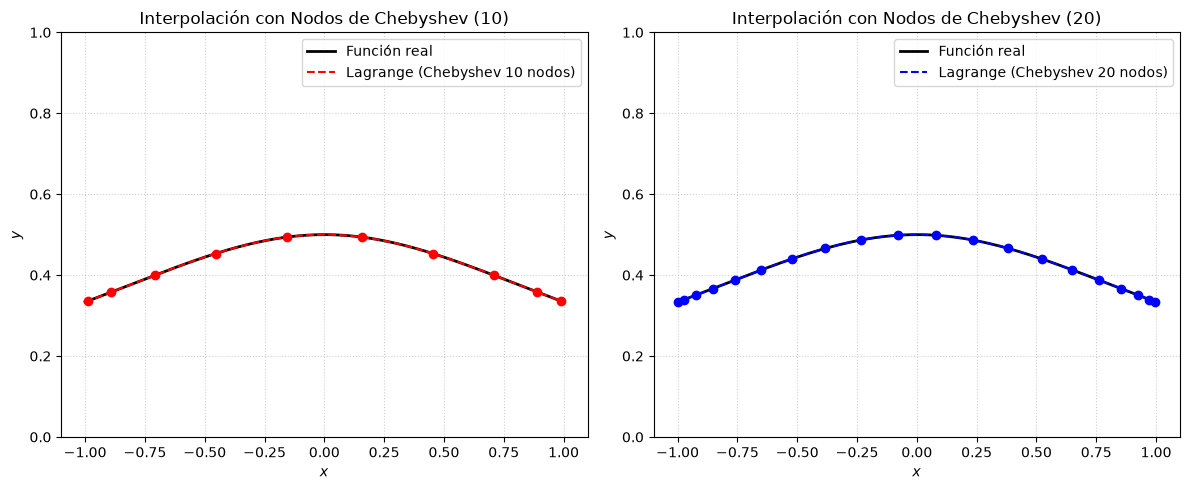

In [18]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import lagrange

# Función de referencia
f = lambda x: 1 / (2 + x**2)
x_dense = np.linspace(-1, 1, 500)
y_true = f(x_dense)

# Función para generar nodos de Chebyshev con índices de i = n-1, n-2, ..., 0
def nodos_chebyshev(n):
    # i va desde n-1 hasta 0
    i = np.arange(n-1, -1, -1)
    # Fórmula de los nodos de Chebyshev en el intervalo [-1, 1]
    xi = np.cos((2 * i + 1) * np.pi / (2 * n))
    return xi

# --- 1. Interpolación con 10 nodos de Chebyshev ---
n_10 = 10
x_10 = nodos_chebyshev(n_10)
y_10 = f(x_10)
poly_10 = lagrange(x_10, y_10)

# --- 2. Interpolación con 20 nodos de Chebyshev ---
n_20 = 20
x_20 = nodos_chebyshev(n_20)
y_20 = f(x_20)
poly_20 = lagrange(x_20, y_20)

# --- REPRESENTACIÓN GRÁFICA ---
%matplotlib inline

plt.figure(figsize=(12, 5))

# Gráfica con 10 nodos
plt.subplot(1, 2, 1)
plt.plot(x_dense, y_true, 'k-', label='Función real', linewidth=2)
plt.plot(x_dense, poly_10(x_dense), 'r--', label='Lagrange (Chebyshev 10 nodos)')
plt.plot(x_10, y_10, 'ro')
plt.title('Interpolación con Nodos de Chebyshev (10)')
plt.xlabel('$x$')
plt.ylabel('$y$')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.ylim(0, 1)

# Gráfica con 20 nodos
plt.subplot(1, 2, 2)
plt.plot(x_dense, y_true, 'k-', label='Función real', linewidth=2)
plt.plot(x_dense, poly_20(x_dense), 'b--', label='Lagrange (Chebyshev 20 nodos)')
plt.plot(x_20, y_20, 'bo')
plt.title('Interpolación con Nodos de Chebyshev (20)')
plt.xlabel('$x$')
plt.ylabel('$y$')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.ylim(0, 1)

plt.tight_layout()
plt.show()

"Sí, es muchísimo mejor representación. Con los puntos equispaciados el polinomio se volvía loco en los extremos por culpa del fenómeno de Runge y oscilaba un montón. Al usar estos nodos, como se concentran más en los bordes, la curva se estabiliza por completo y se ajusta clavada a la función real sin hacer extraños."

Ejercicio 2 calcula las asintotas de la función 3x menos 4 entre 2 x al cuadrado y dibujala /review

--- ESTUDIO DE ASÍNTOTAS ---
Límite en x -> 0 (Asíntota Vertical): -oo
Asíntota Horizontal: y = 0


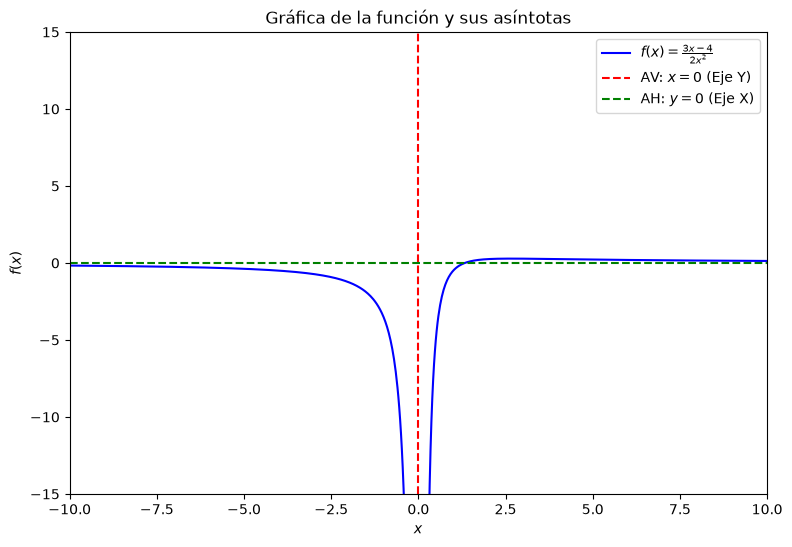

In [9]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt

x = sp.Symbol('x', real=True)

f_sym = (3*x - 4) / (2*x**2)

print("--- ESTUDIO DE ASÍNTOTAS ---")
av = sp.limit(f_sym, x, 0)
print(f"Límite en x -> 0 (Asíntota Vertical): {av}")

ah = sp.limit(f_sym, x, sp.oo)
print(f"Asíntota Horizontal: y = {ah}")

x_vals_neg = np.linspace(-10, -0.05, 400)
x_vals_pos = np.linspace(0.05, 10, 400)

f_num = lambda val: (3*val - 4) / (2*val**2)

plt.figure(figsize=(9, 6))
plt.plot(x_vals_neg, f_num(x_vals_neg), color='blue')
plt.plot(x_vals_pos, f_num(x_vals_pos), color='blue', label=r'$f(x) = \frac{3x - 4}{2x^2}$')

plt.axvline(x=0, color='red', linestyle='--', label='AV: $x = 0$ (Eje Y)')
plt.axhline(y=0, color='green', linestyle='--', label='AH: $y = 0$ (Eje X)')

plt.title('Gráfica de la función y sus asíntotas')
plt.xlabel('$x$')
plt.ylabel('$f(x)$')
plt.xlim(-10, 10)
plt.ylim(-15, 15)
plt.legend()
plt.show()

Ejercicio 3 siendo la función x cuadrado menos 12 y sabiendo que el rectángulo tiene dos vertices superiores di sus dimensiones y calcula su área máxima y además dibuja en papel la función y el rectángulo

--- RESULTADOS ANALÍTICOS ---
Valor óptimo de x: 2
Dimensiones del rectángulo (Ancho x Alto): 4 x 8
Área máxima: 32


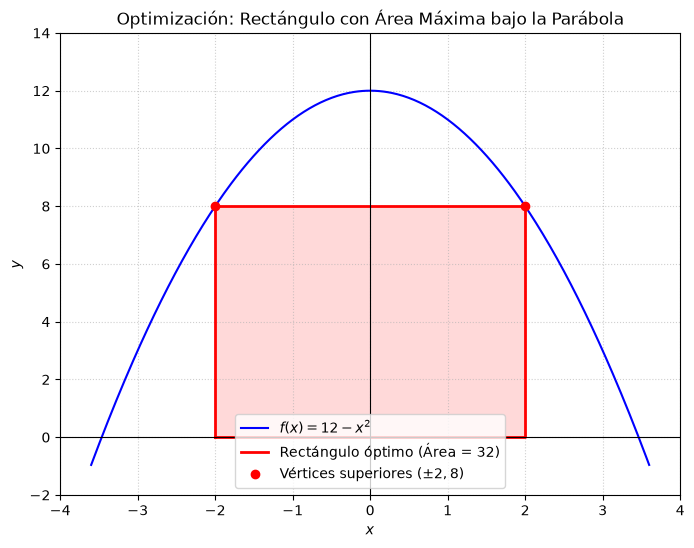

In [10]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt

# --- 1. RESOLUCIÓN SIMBÓLICA CON SYMPY ---
x = sp.Symbol('x', real=True)

# Definir la función de la parábola
f = 12 - x**2

# El área del rectángulo es Base * Altura = (2x) * f(x)
A = 2 * x * f

# Derivar el área respecto a x para encontrar los puntos críticos
dA = sp.diff(A, x)
crit_points = sp.solve(dA, x)

# Filtrar el punto crítico positivo
x_opt = [cp for cp in crit_points if cp > 0][0]
ancho_opt = 2 * x_opt
alto_opt = f.subs(x, x_opt)
area_max = A.subs(x, x_opt)

print("--- RESULTADOS ANALÍTICOS ---")
print(f"Valor óptimo de x: {x_opt}")
print(f"Dimensiones del rectángulo (Ancho x Alto): {ancho_opt} x {alto_opt}")
print(f"Área máxima: {area_max}")


# --- 2. REPRESENTACIÓN GRÁFICA EN JUPYTER ---

# Rango para la parábola
x_vals = np.linspace(-3.6, 3.6, 400)
y_vals = 12 - x_vals**2

# Coordenadas de los 4 vértices del rectángulo óptimo
# Inferiores: (-2, 0), (2, 0)
# Superiores: (-2, 8), (2, 8)
rect_x = [-2, 2, 2, -2, -2]
rect_y = [0, 0, 8, 8, 0]

plt.figure(figsize=(8, 6))
# Dibujar la parábola
plt.plot(x_vals, y_vals, color='blue', label=r'$f(x) = 12 - x^2$')
# Dibujar el rectángulo óptimo
plt.plot(rect_x, rect_y, color='red', linewidth=2, label='Rectángulo óptimo (Área = 32)')
plt.fill(rect_x, rect_y, color='red', alpha=0.15)

# Marcar los vértices superiores en la curva
plt.plot([-2, 2], [8, 8], 'ro', label='Vértices superiores ($\pm 2, 8$)')

plt.title('Optimización: Rectángulo con Área Máxima bajo la Parábola')
plt.xlabel('$x$')
plt.ylabel('$y$')
plt.axhline(0, color='black', linewidth=0.8)
plt.axvline(0, color='black', linewidth=0.8)
plt.xlim(-4, 4)
plt.ylim(-2, 14)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='lower center')
plt.show()

Ejercicio 4 calcula la monotonía y la convexidad de la función 1 entre e elevado a x y dibuja sus intervalos a papel

Primera derivada f'(x): -exp(-x)
Análisis: Al ser siempre negativa, la función es decreciente en todo R.
Segunda derivada f''(x): exp(-x)
Análisis: Al ser siempre positiva, la función es convexa en todo R.



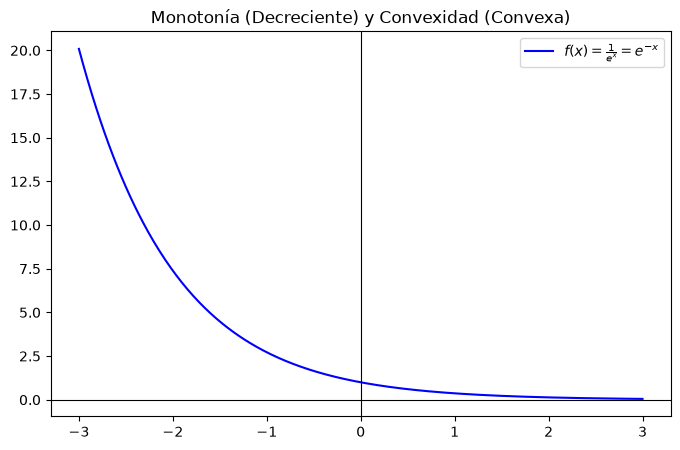

In [15]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt

x = sp.Symbol('x', real=True)

f = 1 / sp.exp(x)

# 1. Estudio de la monotonía (Primera derivada)
df = sp.diff(f, x)
print(f"Primera derivada f'(x): {df}")
print("Análisis: Al ser siempre negativa, la función es decreciente en todo R.")

# 2. Estudio de la convexidad (Segunda derivada)
ddf = sp.diff(f, x, 2)
print(f"Segunda derivada f''(x): {ddf}")
print("Análisis: Al ser siempre positiva, la función es convexa en todo R.\n")

# --- REPRESENTACIÓN GRÁFICA ---

x_vals = np.linspace(-3, 3, 400)
y_vals = 1 / np.exp(x_vals)

plt.figure(figsize=(8, 5))
plt.plot(x_vals, y_vals, color='blue', label=r'$f(x) = \frac{1}{e^x} = e^{-x}$')

plt.title('Monotonía (Decreciente) y Convexidad (Convexa)')
plt.axhline(0, color='black', linewidth=0.8)
plt.axvline(0, color='black', linewidth=0.8)
plt.legend()
plt.show()